# Repository and CI migration planning

This notebook estimates timelines, effort, and team utilization using a discrete-event simulation.
It **does not perform migrations**. The simulation engine is in the adjacent `migration_sim.py` file.

**Getting started:** select a Python kernel → install dependencies on the first run →
adjust the settings → run the cells from top to bottom. After changing settings, rerun the cells below them.
The default workload preserves the original scope: 600 repositories and 200 pipelines.

## 1. Setup

Install dependencies once for the selected kernel. Uncomment the line below if they are not installed yet.

In [1]:
# %pip install simpy pandas matplotlib paretoset

In [2]:
from pathlib import Path
import sys
from copy import deepcopy

# Supports kernels started in the notebook directory or repository root.
MODEL_DIR = next((p for p in (Path.cwd(), Path.cwd() / "notebooks/en/repoMigrationSim")
                  if (p / "migration_sim.py").is_file()), None)
if MODEL_DIR is None:
    raise FileNotFoundError("Start the kernel in the notebook directory or repository root")
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from migration_sim import (
    BASE_CONFIG, preview_plan, run_full_program,
    compare_scenarios, summarize_scenarios,
)


## 2. Settings — edit here

A **wave** is a scheduled stage of the program. A **cohort** is a group of repositories and pipelines
within a wave, with its own migration team. Triage engineers investigate problems; SWAT specialists
handle complex escalations. These two support teams are shared across all cohorts.

Edit the values in `CONFIG.update({...})` below. Parameters omitted from this cell inherit their
values from `BASE_CONFIG`; the advanced settings reference follows the cell.
To change an advanced parameter, add it to the same `CONFIG.update` dictionary.
After making changes, run this cell and all cells below it.

### Workload and allocation

| Parameter | Meaning and effect |
| --- | --- |
| `TOTAL_REPOS`, `TOTAL_PIPES` | Total program workload, in items. `0` disables that workstream; `None` fills every cohort to its limit. |
| `WAVES` | Number of scheduled waves. Empty waves are skipped. |
| `COHORTS_PER_WAVE` | Number of available cohorts per wave. Maximum cohort count: `WAVES × COHORTS_PER_WAVE`. |
| `REPOS_PER_COHORT`, `PIPES_PER_COHORT` | Maximum number of items of each type in one cohort. Total capacity must cover the requested workload. |
| `ALLOCATION_MODE` | `sequential`: fill earlier cohorts to their limits first. `even`: distribute the workload as evenly as possible across all available cohorts. Some cohorts will still be empty if there are too few items. |

**Current plan example:** with limits of 1,000 repositories and 300 pipelines per cohort,
`sequential` assigns all 600 repositories and 200 pipelines to the first cohort.
The other 47 cohorts receive no work.

### Start dates

| Parameter | Meaning and effect |
| --- | --- |
| `WAVE_SPACING_DAYS` | Calendar days between scheduled wave starts. `7` starts a wave every week; `0` allows all waves to start together. This is not a gap after the previous wave finishes. |
| `COHORT_SPACING_DAYS` | Calendar days between scheduled cohort starts within a wave. `0` starts the cohorts together. |
| `TEMPLATES_READY_DAY` | Availability day of shared CI templates, measured from day 0. No cohort can start before this day; the gate applies to both repositories and pipelines. |

A cohort's scheduled start is `(wave number − 1) × WAVE_SPACING_DAYS +
(cohort number − 1) × COHORT_SPACING_DAYS`. The template availability gate is then applied,
and the start is moved to the next working time if necessary. Waves can overlap.

### Staffing

| Parameter | Meaning and effect |
| --- | --- |
| `REPO_ENGINEERS_PER_COHORT` | Repository migration engineers assigned to each active cohort containing repositories. Each engineer handles one task at a time. |
| `CI_ENGINEERS_PER_COHORT` | Equivalent staffing for CI pipelines. Increasing it helps when this workstream limits the finish date. |
| `TRIAGE_ENGINEERS_SHARED` | Shared pool for problem investigation and support after migration. Insufficient capacity creates queues; hypercare uses this same pool. |
| `SWAT_CORE_CAPACITY` | Shared pool of specialists for complex escalations. Additional specialists help only when such requests occur. |

Staffing values must be positive integers. Each cohort gets its own Repo/CI team,
so overlapping cohorts increase total staffing. More engineers do not guarantee a proportional
reduction in duration: other queues, scheduling, or support may limit progress.

### Calendar and support after migration

| Parameter | Meaning and effect |
| --- | --- |
| `BUSINESS_HOURS_ONLY` | `True`: work only during the configured hours. `False`: work continuously, 24/7; working-hour and weekend settings are ignored. |
| `WORKDAY_START_HOUR`, `WORKDAY_END_HOUR` | Start and end of the working window, from 0 to 24. `[9, 17)` provides 8 working hours; the start must be earlier than the end. |
| `WEEKENDS_OFF` | With the business calendar enabled, `True` excludes Saturdays and Sundays; `False` allows work every day during the configured hours. |
| `HYPERCARE_ENABLED` | Enables support after each cohort's migration finishes. It adds triage effort and affects the finish date including support. |
| `HYPERCARE_WEEKS` | Number of nominal support weeks: one week means 5 sessions on separate working days. The value × 5 must be an integer. In 24/7 mode, sessions follow calendar days. |
| `HYPERCARE_HOURS_PER_DAY` | Working hours per daily session, using one triage engineer per cohort. For example, `1 × 5 × 2 = 10` person-hours of support. Must not exceed the working window. |

### Reproducibility and scenario comparison

| Parameter | Meaning and effect |
| --- | --- |
| `SEED` | Integer determining the sequence of random events in one run: complexity, durations, and rework. The same seed and settings reproduce the same result. |
| `SEEDS` | List of seeds for scenario comparison. `list(range(42, 52))` produces 10 runs per scenario. A longer list provides more detail about variability but takes longer to compute. |
| `SCENARIOS` | Dictionary of scenario names and CONFIG overrides. An empty dictionary `{}` uses the baseline configuration. For example, `{"CI_ENGINEERS_PER_COHORT": 6}` changes only CI staffing. Each seed in `SEEDS` replaces `CONFIG["SEED"]` for that comparison run. |

In [3]:
CONFIG = deepcopy(BASE_CONFIG)
CONFIG.update({
    "TOTAL_REPOS": 600,  # Total repositories, in items
    "TOTAL_PIPES": 200,  # Total CI pipelines, in items
    "WAVES": 16,  # Available waves; empty waves are skipped
    "COHORTS_PER_WAVE": 3,  # Available migration groups per wave
    "ALLOCATION_MODE": "sequential",  # sequential: fill earlier cohorts; even: distribute evenly
    "REPOS_PER_COHORT": 1000,  # Maximum repositories per cohort
    "PIPES_PER_COHORT": 300,  # Maximum pipelines per cohort
    "WAVE_SPACING_DAYS": 7,  # Calendar days between wave starts
    "COHORT_SPACING_DAYS": 0,  # Calendar days between cohort starts within a wave
    "TEMPLATES_READY_DAY": 1,  # Earliest allowed start, measured from program day 0
    "REPO_ENGINEERS_PER_COHORT": 4,  # Repo engineers per cohort containing repositories
    "CI_ENGINEERS_PER_COHORT": 4,  # CI engineers per cohort containing pipelines
    "TRIAGE_ENGINEERS_SHARED": 3,  # Shared engineers for problem investigation and hypercare
    "SWAT_CORE_CAPACITY": 2,  # Shared specialists for complex escalations
    "BUSINESS_HOURS_ONLY": True,  # True: business calendar; False: continuous 24/7 work
    "WORKDAY_START_HOUR": 9,  # Working window start hour, inclusive
    "WORKDAY_END_HOUR": 17,  # Working window end hour, exclusive
    "WEEKENDS_OFF": True,  # Exclude Saturday/Sunday when using the business calendar
    "HYPERCARE_ENABLED": True,  # Support after each cohort finishes migration
    "HYPERCARE_WEEKS": 1,  # Five daily sessions per nominal week
    "HYPERCARE_HOURS_PER_DAY": 2,  # Hours per session, using one triage engineer per cohort
    "SEED": 42,  # Seed for one run; not the number of runs
})

# Comparison settings: 10 repetitions per scenario.
SEEDS = list(range(42, 52))
SCENARIOS = {
    "Baseline team": {},
    "More CI engineers": {"CI_ENGINEERS_PER_COHORT": 6},
    "More Repo engineers": {"REPO_ENGINEERS_PER_COHORT": 6},
    "Even allocation across waves": {"ALLOCATION_MODE": "even"},
}


### Advanced model parameters

These values are inherited from `BASE_CONFIG` in `migration_sim.py`. The next code cell displays
the complete effective configuration. Add overrides to `CONFIG.update` above to keep all changes
in one place.

| Parameter | Meaning and units |
| --- | --- |
| `REPO_DIST`, `PIPE_DIST` | Proportions of `simple`, `medium`, and `complex` tasks for repositories and pipelines. Each dictionary must sum to 1. For example, `0.7` means 70% of tasks. Each task's type is chosen randomly. |
| `REPO_TIMES`, `PIPE_TIMES` | `(minimum, maximum)` ranges of working hours for initial work, by task type. Durations are sampled uniformly within the range, then multiplied by the duration scaler. |
| `REPO_REWORK_PROB`, `PIPE_REWORK_PROB` | Base probability of a single rework cycle after initial work. `0.01` means 1%. The effective probability is also multiplied by the workstream's rework scaler. |
| `REPO_REWORK_TIME`, `PIPE_REWORK_TIME` | Range of additional working hours when rework occurs. Multiplied by the workstream's duration scaler; triage and SWAT effort are added separately. |
| `TRIAGE_TIME_REPO`, `TRIAGE_TIME_PIPE` | Range of working hours a triage engineer spends investigating one rework case. The migration engineer remains assigned to the task while waiting for support to finish. |
| `ESCALATION_PROB_COMPLEX_REPO`, `ESCALATION_PROB_COMPLEX_PIPE` | Probability of requesting SWAT **when a complex task requires rework**, rather than across all tasks. For example, `0.25` means one quarter of those cases. |
| `SWAT_TIME_REPO`, `SWAT_TIME_PIPE` | Range of working hours a SWAT specialist spends on one escalation. |
| `SECURITY_CHAMPIONS_ENABLED` | Enables faster triage through trained team members. The model represents this only as a time multiplier; no additional engineers are created. |
| `TRIAGE_ACCEL_FACTOR` | Triage duration multiplier when security champions are enabled. `0.9` means 10% less time. Does not apply to hypercare. |
| `DURATION_SCALER_REPO`, `DURATION_SCALER_PIPE` | Initial duration multipliers for initial work and rework. `0.95` means 5% less time than the original ranges; `1` leaves them unchanged. Do not scale triage or SWAT. |
| `REWORK_SCALER_REPO`, `REWORK_SCALER_PIPE` | Initial rework probability multipliers. For example, `0.01 × 0.85 = 0.0085`, or 0.85%. |
| `IMPR_MIN`, `IMPR_MAX` | Bounds for random improvements between waves. With `0.01`–`0.10`, the next wave's duration scalers decrease by 1–10% relative to the previous wave; rework probability scalers decrease by half the sampled percentage. Improvements accumulate. |
| `IMPROVEMENT_HOOK` | `None` uses the default improvement rule. To customize it, supply a function `(state, wave_index, rng, cfg) → dict` returning new `dur_repo`, `dur_pipe`, `rwrk_repo`, and `rwrk_pipe` scalers. This requires editing the model in Python. |

The default rule keeps duration scalers at or above `0.3` and rework scalers at or above `0.05`.
Improvements follow the scheduled wave number, including empty waves, and are assigned in advance.
They do not wait for the previous wave to finish or learn from its actual results.

Example overrides inside the existing `CONFIG.update({...})` dictionary:

```python
"REPO_REWORK_PROB": 0.03,       # Base repository rework probability: 3%
"REPO_TIMES": {"simple": (0.5, 1), "medium": (2, 4), "complex": (8, 16)},
"IMPR_MIN": 0.05,              # Equal bounds give a fixed 5% improvement
"IMPR_MAX": 0.05,
```

### Assumptions and units

- Day 0 is a nominal Monday at 00:00. Holidays and leave are not modeled.
- Task durations use working hours; the business calendar pauses work at night and on days off.
- `PersonDays` means person-days of **8 hours**. Durations in `Days`/`(d)` use calendar days.
- `Month` means 30.4375-day intervals from day 0, numbered from 0; these are not calendar months.
- Program finish dates are measured **from day 0**, including template and scheduling delays.
  Migration completion, support completion, and the span after the first start are reported separately.
- Task P95 is the completion time of 95% of tasks **relative to their cohort's actual start**, including queueing.
  The summary reports the highest cohort P95; samples smaller than 100 tasks use the maximum instead.
- Hypercare has one session on each of 5 working days per week, starting after cohort completion.
  Sessions may be delayed if triage engineers are unavailable; engineers are released between sessions.
- Repo/CI utilization uses their cohort's migration window; triage/SWAT use the window from the first start
  through the end of support. Only active work counts in the numerator. Engineers with no recorded work
  are omitted from the detailed tables.
- Peak staffing counts assigned Repo/CI engineers across overlapping migrations plus the full shared
  triage/SWAT pools. Each cohort has its own team; engineers are not automatically reassigned between cohorts.
- Repositories and pipelines migrate independently. Probabilities and durations are model assumptions.
  Improvements between waves are predefined rather than inferred from the previous wave's results.

In [4]:
# Complete effective configuration, including probabilities, durations, and automation.
display(pd.DataFrame([{"Parameter": k, "Value": str(v)} for k, v in CONFIG.items()]))

,Parameter,Value
0,TOTAL_REPOS,600
1,TOTAL_PIPES,200
2,ALLOCATION_MODE,sequential
3,WAVES,16
4,COHORTS_PER_WAVE,3
5,WAVE_SPACING_DAYS,7
6,COHORT_SPACING_DAYS,0
7,REPOS_PER_COHORT,1000
8,PIPES_PER_COHORT,300
9,REPO_ENGINEERS_PER_COHORT,4


## 3. Preview and validate the plan

Invalid parameters and insufficient total capacity raise an explanatory error before simulation.
Empty cohorts appear in the plan but are not launched.

In [5]:
plan = preview_plan(CONFIG)
active = int(plan["Active"].sum())
display(Markdown(f"**Active cohorts: {active} of {len(plan)}.** "
                 f"Repositories: {plan.Repos.sum()}, pipelines: {plan.Pipelines.sum()}."))
if active == 1 and len(plan) > 1:
    display(Markdown("**Note:** the entire workload was assigned to one cohort. "
                     "To distribute it across waves, set `ALLOCATION_MODE = 'even'` "
                     "or reduce the per-cohort limits."))
elif active == 0:
    display(Markdown("The plan is empty: specify a nonzero migration workload."))
display(plan.round(2))

**Active cohorts: 1 of 48.** Repositories: 600, pipelines: 200.

**Note:** the entire workload was assigned to one cohort. To distribute it across waves, set `ALLOCATION_MODE = 'even'` or reduce the per-cohort limits.

,Wave,Cohort,Repos,Pipelines,Active,Start(d),RepoEngineers,CIEngineers
0,1,1,600,200,True,1.38,4,4
1,1,2,0,0,False,NaN,0,0
2,1,3,0,0,False,NaN,0,0
3,2,1,0,0,False,NaN,0,0
4,2,2,0,0,False,NaN,0,0
5,2,3,0,0,False,NaN,0,0
6,3,1,0,0,False,NaN,0,0
7,3,2,0,0,False,NaN,0,0
8,3,3,0,0,False,NaN,0,0
9,4,1,0,0,False,NaN,0,0


## 4. Run one scenario

The same seed and settings produce a reproducible result.
One run is an example of a possible outcome; variability is assessed in the comparison section.

In [6]:
out = run_full_program(CONFIG)
hours = out["usage_totals_df"]["Hours"].sum()
summary = pd.DataFrame([
    ("Repositories processed", out["processed_repos"], "items"),
    ("Pipelines processed", out["processed_pipes"], "items"),
    ("First actual start", out["program_start_hour"] / 24, "day from day 0"),
    ("Migration complete", out["migration_finish_days"], "day from day 0"),
    ("Support complete", out["overall_finish_days"], "day from day 0"),
    ("First start through end of support", out["active_span_days"], "calendar days"),
    ("Effort including support", hours, "person-hours"),
    ("Effort / 8", hours / 8, "person-days"),
    ("Peak assigned staffing", out["peak_engineers"], "people"),
    ("Worst repository P95", out["worst_repo_p95_days"], "days from cohort start"),
    ("Worst pipeline P95", out["worst_pipe_p95_days"], "days from cohort start"),
], columns=["Metric", "Value", "Unit"])
display(summary.round(2))
display(pd.DataFrame(out["rework_stats"]).T.round(2))

,Metric,Value,Unit
0,Repositories processed,600.00,items
1,Pipelines processed,200.00,items
2,First actual start,1.38,day from day 0
3,Migration complete,45.49,day from day 0
4,Support complete,51.46,day from day 0
5,First start through end of support,50.08,calendar days
6,Effort including support,1620.58,person-hours
7,Effort / 8,202.57,person-days
8,Peak assigned staffing,13.00,people
9,Worst repository P95,43.11,days from cohort start


,count,rate_pct,escalations,main_hours,rework_hours,triage_hours,swat_hours
repos,3.0,0.5,0.0,1022.25,6.69,5.68,0.0
pipes,4.0,2.0,0.0,556.86,11.80,7.31,0.0


## 5. Timeline and utilization

Wave bars include support. Team utilization averages across all assigned engineers,
including those with no recorded work. Individual details are in the next section.

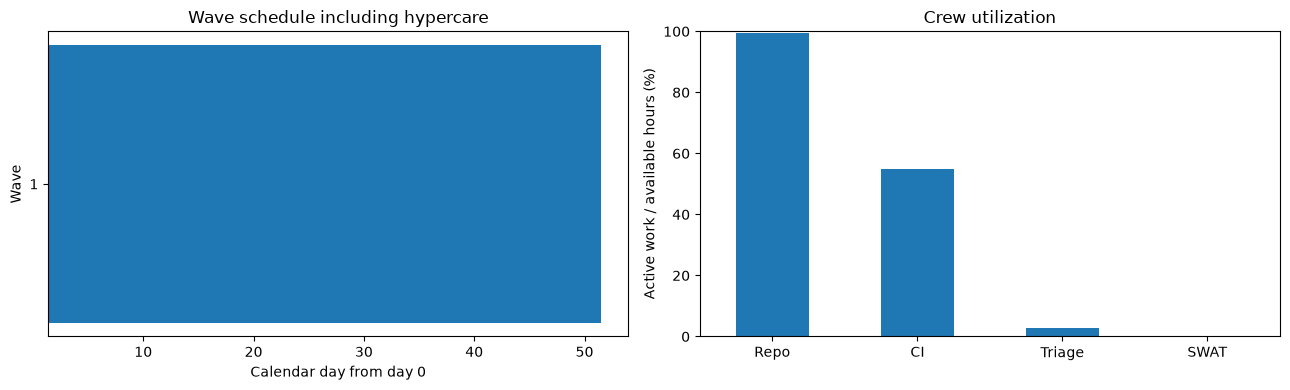

In [7]:
if out["results"]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    waves = out["waves_df"]
    axes[0].barh(waves["Wave"].astype(str), waves["WaveDuration(d)"], left=waves["WaveStart(d)"])
    axes[0].set(xlabel="Calendar day from day 0", ylabel="Wave", title="Wave schedule including hypercare")
    crew_hours = out["usage_totals_df"].groupby("Crew")["Hours"].sum()
    from migration_sim import business_hours_between
    migration_capacity = sum(business_hours_between(r.start_hour, r.finish_hour, CONFIG)
                             * CONFIG["REPO_ENGINEERS_PER_COHORT"]
                             for r in out["results"] if r.repos_planned)
    ci_capacity = sum(business_hours_between(r.start_hour, r.finish_hour, CONFIG)
                      * CONFIG["CI_ENGINEERS_PER_COHORT"]
                      for r in out["results"] if r.pipes_planned)
    shared_window = business_hours_between(out["program_start_hour"], out["program_end_hour"], CONFIG)
    capacity = pd.Series({"Repo": migration_capacity, "CI": ci_capacity,
                          "Triage": shared_window * CONFIG["TRIAGE_ENGINEERS_SHARED"],
                          "SWAT": shared_window * CONFIG["SWAT_CORE_CAPACITY"]})
    crew_load = 100 * crew_hours.reindex(capacity.index, fill_value=0) / capacity.replace(0, float("nan"))
    crew_load.fillna(0).plot.bar(ax=axes[1], rot=0)
    axes[1].set(ylabel="Active work / available hours (%)", title="Crew utilization", ylim=(0, 100))
    fig.tight_layout()
    plt.show()
else:
    print("No work to display.")

## 6. Detailed tables

`out` contains raw work segments, cohort statistics, and aggregates.
`Hours` means person-hours, `PersonDays` means 8-hour person-days, and `LoadPct` is active utilization in percent.

In [8]:
display(out["waves_df"].round(2))
display(out["usage_load_df"].round(2))
monthly = out["usage_monthly_df"]
display(monthly.groupby(["Month", "Crew"], as_index=False)[["Hours", "PersonDays"]].sum().round(2))
# For monthly detail by engineer: display(monthly.round(2))
# For raw work segments: display(out["usage_df"])

,Wave,WaveStart(d),WaveEnd(d),WaveDuration(d),WaveDuration(mo)
0,1,1.38,51.46,50.08,1.65


,Crew,Engineer,Hours,PersonDays,LoadPct
0,Repo,Repo_1.1:1,258.54,32.32,99.88
1,Repo,Repo_1.1:3,257.44,32.18,99.45
2,Repo,Repo_1.1:4,256.85,32.11,99.22
3,Repo,Repo_1.1:2,256.11,32.01,98.94
4,CI,CI_1.1:4,146.09,18.26,56.44
5,CI,CI_1.1:1,144.61,18.08,55.86
6,CI,CI_1.1:2,141.59,17.70,54.70
7,CI,CI_1.1:3,136.37,17.05,52.68
8,Triage,Triage:2,8.15,1.02,2.81
9,Triage,Triage:1,7.97,1.00,2.75


,Month,Crew,Hours,PersonDays
0,0,CI,568.66,71.08
1,0,Repo,674.21,84.28
2,0,Triage,11.09,1.39
3,1,Repo,354.73,44.34
4,1,Triage,11.89,1.49


## 7. Scenario comparison and variability

Scenarios and seeds are defined in the settings section. Each scenario runs with every seed.
The table reports median finish time, the P10–P90 outcome range, and mean effort.
This is **empirical simulation variability**, not a confidence interval or a delivery guarantee.
Ten runs are enough for an initial exploration; increase the seed list to assess tail outcomes.
Identical seeds do not ensure identical task samples when scheduling or staffing changes.

`Pareto = True` means no other compared scenario is at least as good on both peak staffing and
median finish time including support, and strictly better on at least one of them.
Cost and effort are not part of this Pareto criterion.

,Scenario,Runs,PeakEng,MigrationMedianDays,FinishMedianDays,FinishP10Days,FinishP90Days,MeanHours,Pareto
0,Baseline team,10,13,49.55,53.46,50.46,58.56,1729.76,True
1,More CI engineers,10,15,49.58,54.96,51.26,58.56,1740.75,False
2,More Repo engineers,10,15,32.11,38.46,36.36,39.76,1751.49,True
3,Even allocation across waves,10,29,105.64,112.46,109.46,112.46,1743.11,False


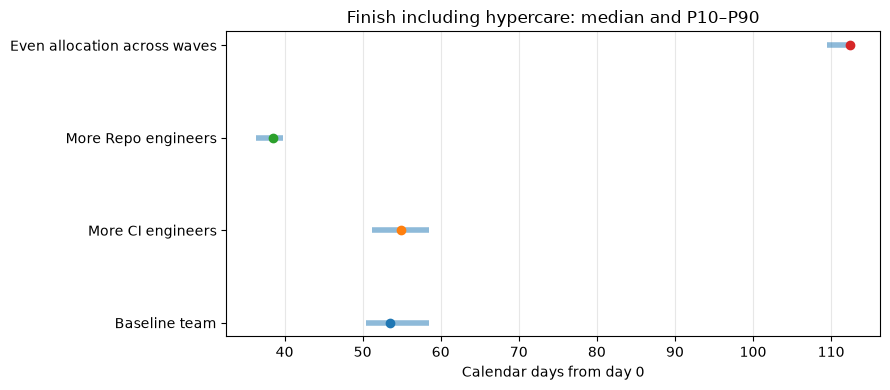

In [9]:
runs = compare_scenarios(CONFIG, SCENARIOS, SEEDS)
comparison = summarize_scenarios(runs)
display(comparison.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for i, row in comparison.iterrows():
    ax.hlines(i, row.FinishP10Days, row.FinishP90Days, linewidth=4, alpha=.5)
    ax.plot(row.FinishMedianDays, i, "o")
ax.set(yticks=range(len(comparison)), yticklabels=comparison.Scenario,
       xlabel="Calendar days from day 0", title="Finish including hypercare: median and P10–P90")
ax.grid(axis="x", alpha=.3)
fig.tight_layout()
plt.show()
# Raw simulation runs: display(runs)

## 8. Export (optional)

Uncomment the cell to save tables and settings next to the notebook.
Exporting again replaces the files in `exports`.

In [10]:
# import json
# export_dir = MODEL_DIR / "exports"
# export_dir.mkdir(exist_ok=True)
# summary.to_csv(export_dir / "summary.csv", index=False, encoding="utf-8-sig")
# plan.to_csv(export_dir / "plan.csv", index=False)
# comparison.to_csv(export_dir / "scenarios.csv", index=False, encoding="utf-8-sig")
# runs.to_csv(export_dir / "runs.csv", index=False, encoding="utf-8-sig")
# out["usage_load_df"].to_csv(export_dir / "workload.csv", index=False)
# (export_dir / "settings.json").write_text(
#     json.dumps({"config": CONFIG, "scenarios": SCENARIOS, "seeds": SEEDS},
#                ensure_ascii=False, indent=2, default=str), encoding="utf-8")